# Makemore Part 3: Activations, Gradients and BatchNorm

## Notes

1. **Mean** — center of the distribution. Want `hpreact` mean near 0, or activations are skewed one direction before `tanh` even sees them.

2. **Variance** — average squared spread around the mean.

3. **Std** — `sqrt(variance)`, same info but in real units so you can compare directly to `tanh`'s range of (-1, 1).

**Why it matters:**

- **Low std** → values bunched tightly near the mean → in `hpreact`, most values sit close to 0 → after `tanh`, stuck in the near-linear middle region → weak, underused nonlinearity.
- **High std** → values spread widely, many far from 0 → in `hpreact`, pushes values into the extremes → `tanh` saturates there → dead gradients.
- **"Just right" std** → spread wide enough to use `tanh`'s dynamic range, not so wide that most values sit in the flat saturated zones.

4.

**NOTE 1**: We want our initial training loss close to `-ln(1/num_output_neurons)` — our target initial loss. If it's higher than that, it means we have too much variance: the softmax is producing a very peaked, confident distribution that happens to be confidently wrong.

- **FIX**: scale down the output layer weights (multiply by a small decimal like 0.01) and set bias to 0 initially.

- **CAUTION — don't overdo the same trick on hidden layers**: this fix works for the *output* layer because we want low-confidence logits at init, and there's no activation function after it to worry about. But if you scale weights *feeding into* `tanh` too aggressively, `hpreact` becomes tiny, everything sits near 0, and `tanh` is nearly linear there. Gradients flow fine, but you've thrown away the nonlinearity — the signal becomes too weak to represent anything useful.
  - This is **not** the dead neuron problem — it's the opposite failure mode.
  - **Dead neuron** = weights *too large* → `hpreact` saturates `tanh` at ±1 → `tanh'(x) ≈ 0` → gradient stops flowing → neuron stops learning.
  - **Weak signal** = weights *too small* → `tanh` stays near-linear → nonlinearity wasted, but gradients still flow fine.

**NOTE 2:** Bias is not useful in a layer that feeds into BatchNorm.

-   **Reason:** BatchNorm subtracts the batch mean from every example. Since bias is a constant added equally to every example, subtracting the mean cancels it out entirely — it has zero effect on the output and receives no useful gradient. BatchNorm's own learnable shift (`bnbias` / `beta`) replaces that role, so the layer's bias becomes redundant.

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [3]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [5]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words:
  
  #print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

In [6]:
X.shape, X.dtype, Y.shape, Y.dtype


(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [13]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [7]:
C = torch.randn((27, 2))


In [8]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [9]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [10]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)


In [11]:
h

tensor([[ 0.9539, -0.7612,  0.3522,  ...,  0.2584,  0.9675,  0.9850],
        [ 0.9382, -0.5527,  0.0818,  ..., -0.9927,  0.9694,  0.9381],
        [-0.9753, -0.9947,  0.9705,  ...,  0.9385,  0.9154, -0.1368],
        ...,
        [ 0.8478,  0.9714, -0.3771,  ..., -1.0000,  0.9029,  0.9999],
        [-1.0000,  0.8746,  0.9160,  ..., -0.9455,  0.4373,  0.9997],
        [ 0.9997,  0.9408,  0.9997,  ...,  0.0604, -0.9449,  1.0000]])

In [12]:
h.shape

torch.Size([228146, 100])

In [13]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [14]:
logits = h @ W2 + b2


In [15]:
logits.shape


torch.Size([228146, 27])

In [16]:
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)

In [18]:
prob.shape

torch.Size([228146, 27])

In [21]:
loss = -prob[torch.arange(228146), Y].log().mean()
loss

tensor(14.6879)

In [22]:
# ------------ now made respectable :) ---------------


In [23]:
Xtr.shape, Ytr.shape # dataset


(torch.Size([182625, 3]), torch.Size([182625]))

In [24]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]


In [25]:
sum(p.nelement() for p in parameters) # number of parameters in total


11897

In [26]:
for p in parameters:
  p.requires_grad = True

In [27]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [28]:
lri = []
lossi = []
stepi = []

In [29]:
for i in range(200000):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))
  
  # forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

#print(loss.item())

In [31]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1224, grad_fn=<NllLossBackward0>)

In [32]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1609, grad_fn=<NllLossBackward0>)

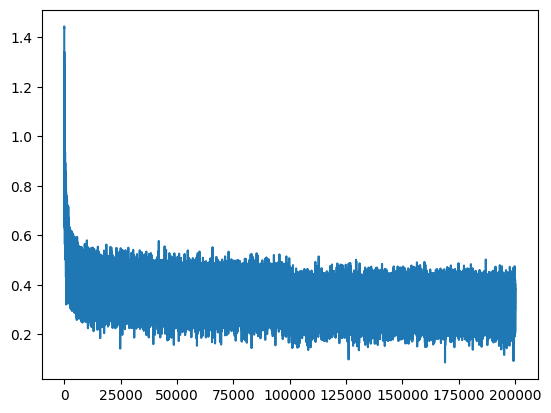

In [35]:
plt.plot(stepi, lossi)

In [ ]:
print(torch.tensor(1/27).log()) # i.e 1 / no. of neurons at output layer

tensor(-3.2958)


## 1st Bottleneck: The straight line in the plot

At init, your network has learned nothing — it should be maximally uncertain, i.e. predicting each of the 27 characters with equal probability 1/27. Cross-entropy loss for a correct label under a uniform guess is exactly -ln(1/27) = 3.30.

If your actual initial loss is much higher than that (say 20+), it means the network isn't guessing uniformly — it's guessing confidently and wrong (some logits are large, softmax is peaked on the wrong character). Early training then wastes iterations just squashing those falsely-confident logits back down toward reasonable magnitude before any real learning starts. That's the "hockey stick" — a flat/slow start followed by a sharp drop once the logits normalize, then the real learning curve. That wasted phase is the bottleneck — you're burning steps fixing an artifact of bad init, not learning structure in the data.

**FIX:** in the original (unfixed) init, W2 and b2 were both drawn from torch.randn(...) with no scaling — full standard-normal variance — which gives the output layer large, essentially random logits at init, so softmax comes out sharply peaked on some arbitrary character (confidently wrong) instead of flat. The fix is two lines only: multiply W2 by a small constant like 0.01 right after initializing it, and initialize b2 as torch.zeros(27) instead of torch.randn(27). Everything else — C, W1, b1, the forward pass, the training loop — stays exactly

In [52]:
g = torch.Generator().manual_seed(2147483647)
n_embd = 10
n_hidden = 100

# embedding table + hidden layer — unchanged from Part 2
C  = torch.randn((27, n_embd),            generator=g)
#W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) 
#b1 = torch.randn(n_hidden,                generator=g)

# OUTPUT layer — this is the actual fix
W2 = torch.randn((n_hidden, 27), generator=g) * 0.01   # scale down
b2 = torch.zeros(27)                                    # zero, not random

parameters = [C, W1, b1, W2, b2]
for p in parameters:
    p.requires_grad = True

In [54]:
# Lets verify if the changes worked for us

Xb, Yb = Xtr[:32], Ytr[:32]  # one batch, no training yet

emb = C[Xb]
embcat = emb.view(emb.shape[0], -1)
hpreact = embcat @ W1 + b1    # h pre activation i.e before tanh is applied
h = torch.tanh(hpreact)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Yb)

print(loss.item())          # should be close to 3.30
print(torch.tensor(1/27).log().neg())  # your target, for comparison



# SUCCESS: If our initial loss is close to -ln(1/27) i.e 3.29

3.298349618911743
tensor(3.2958)


## 2nd Bottleneck: `tanh` Saturation (Hidden Layer)

### The problem, from your own plots

**`h` histogram** (`plt.hist(h.view(-1).tolist(), 50)`):
Almost all values are piled at exactly **-1** and **+1**, with almost nothing in between. That's not what a healthy `tanh` output should look like — it should spread across the full range.

(array([1266.,   96.,   58.,   32.,   27.,   22.,   24.,   16.,   26.,
          23.,    8.,   12.,   13.,   16.,   10.,    8.,    6.,   11.,
          12.,   10.,   11.,   11.,    6.,    8.,   13.,    7.,   21.,
           2.,    7.,   13.,   11.,    3.,   13.,   11.,   16.,   16.,
          25.,   16.,   16.,   11.,   15.,   17.,   22.,   16.,   36.,
          31.,   33.,   56.,   68.,  973.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

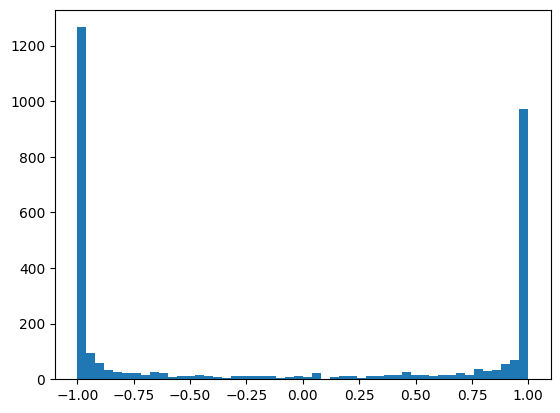

In [43]:
plt.hist(h.view(-1).tolist(), 50)

**`hpreact` histogram** (`plt.hist(hpreact.view(-1).tolist(), 50)`):
This is the *cause*. Values range roughly from **-20 to +18** — way too wide. `tanh` squashes anything with `|x|` beyond ~2-3 straight to ±1. Since most of your `hpreact` values are way out past that range, `tanh` has nothing left to do but flatten them to the extremes — hence the spike histogram in `h`.

(array([  2.,   0.,   0.,   3.,   0.,   1.,   1.,   5.,  15.,  11.,  19.,
         26.,  31.,  57.,  58.,  77., 106., 111., 108., 155., 165., 202.,
        198., 198., 200., 218., 207., 139., 140., 138., 128., 101.,  94.,
         85.,  44.,  43.,  40.,  19.,  17.,  11.,   8.,   3.,   5.,   3.,
          5.,   1.,   1.,   0.,   0.,   1.]),
 array([-2.04386940e+01, -1.96203490e+01, -1.88020041e+01, -1.79836591e+01,
        -1.71653142e+01, -1.63469692e+01, -1.55286243e+01, -1.47102793e+01,
        -1.38919344e+01, -1.30735894e+01, -1.22552444e+01, -1.14368995e+01,
        -1.06185545e+01, -9.80020958e+00, -8.98186462e+00, -8.16351967e+00,
        -7.34517471e+00, -6.52682976e+00, -5.70848480e+00, -4.89013985e+00,
        -4.07179489e+00, -3.25344994e+00, -2.43510498e+00, -1.61676003e+00,
        -7.98415070e-01,  1.99298859e-02,  8.38274841e-01,  1.65661980e+00,
         2.47496475e+00,  3.29330971e+00,  4.11165466e+00,  4.92999962e+00,
         5.74834457e+00,  6.56668953e+00,  7.38503

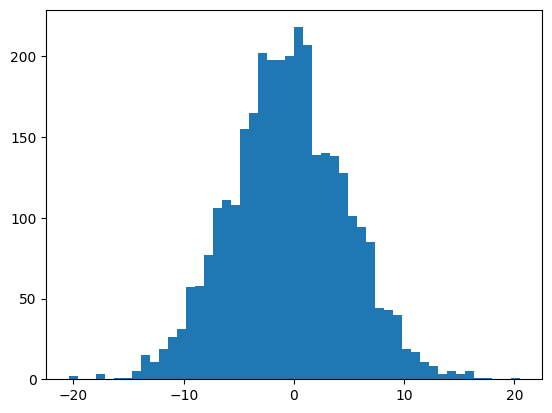

In [44]:
plt.hist(hpreact.view(-1).tolist(), 50)

**Saturation map** (`plt.imshow(h.abs() > 0.99, cmap='gray')`):
Each pixel = one neuron, one example. **White = saturated** (`|h| > 0.99`). This grid is mostly white — meaning most neurons, for most examples, are stuck at the extremes.


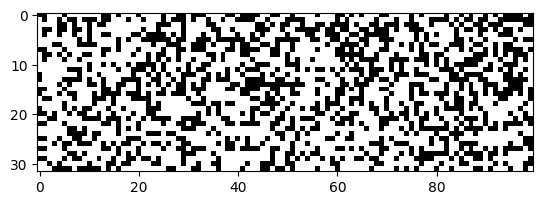

In [45]:
plt.imshow(h.abs() > 0.99, cmap='gray')

### Why this is bad: the dead neuron problem

`tanh'(x) = 1 - tanh(x)²`

When `tanh(x)` is close to ±1, `tanh(x)²` is close to 1, so the derivative is close to **0**. During backprop, this derivative multiplies into the chain rule for every gradient flowing through that neuron. A near-zero derivative means a near-zero gradient — **that neuron gets essentially no update, for that example.**

- **`abs() > 0.99` as the practical threshold**: this isn't a magic constant — it's just "close enough to ±1 that the gradient is negligible in practice." Above that threshold, learning for that neuron (on that example) has effectively stopped.
- **A neuron is only truly "dead"** if it's saturated like this across **every single example** in the training set — i.e. an entire column in the saturation map is all white. If that happens, no example ever produces a useful gradient for that neuron, so its incoming weights never update again, for the rest of training. It's permanently stuck, no matter how much longer you train.
- **If a column is all dead**: the fix isn't at the individual-neuron level — it means your init is bad enough that this is happening systematically. Fix the init at the layer level (below), don't patch neurons individually.

### The fix: scaled init using `gain / sqrt(fan_in)`

You're currently doing something like `W1 = torch.randn(...) * some_guessed_constant`, which is what produced the -20 to +18 spread. Instead, scale by a principled factor based on **fan-in** (number of inputs into the layer) and a **gain** specific to your activation function:


In [ ]:
fan_in = W1.shape[0]           # n_embd * block_size
gain = 5/3                      # gain for tanh specifically
std = gain / (fan_in ** 0.5)
std

0.3042903097250923

In [51]:
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * std
b1 = torch.randn(n_hidden, generator=g) * 0.01     # small, not zero — or zero is fine too

**Why `5/3` for tanh specifically:** `tanh` squashes its input, which shrinks variance every time data passes through it. The gain compensates for that shrinkage so variance stays roughly constant layer to layer instead of decaying or exploding as you stack more layers. Different activations shrink/preserve variance differently, so each has its own gain:

| Activation | Gain |
|---|---|
| Linear / Identity | 1 |
| Tanh | 5/3 |
| ReLU | √2 |
| Leaky ReLU | √(2 / (1 + slope²)) |



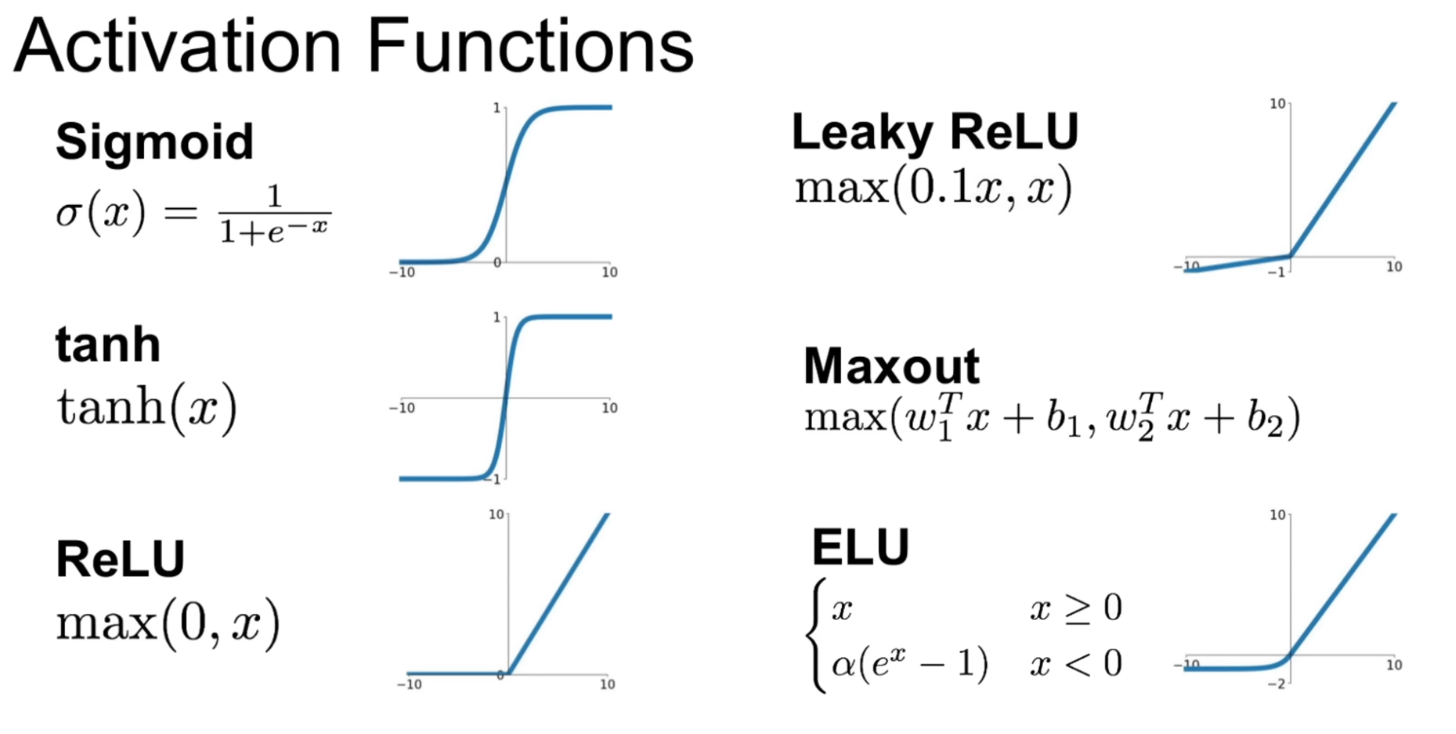

In [46]:
from PIL import Image
img = Image.open('./part3-activation-funcs.png')  # path to your file
img


### Verify the fix — rerun the same three plots

**What you should see after the fix:**
- `hpreact` histogram: narrower, centered near 0, no more ±20 tails
- `h` histogram: spread across the full (-1, 1) range, not just spiked at the ends
- Saturation map: mostly black now (few saturated neurons), not mostly white


0.06750000268220901


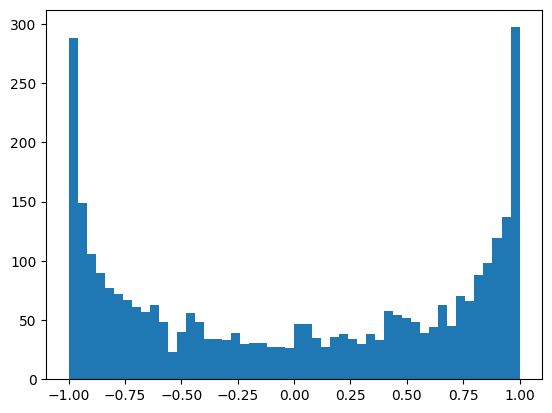

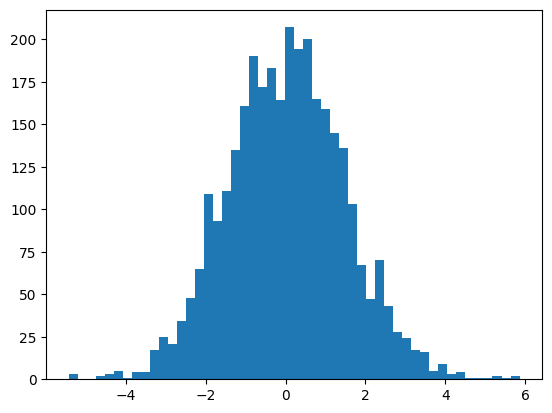

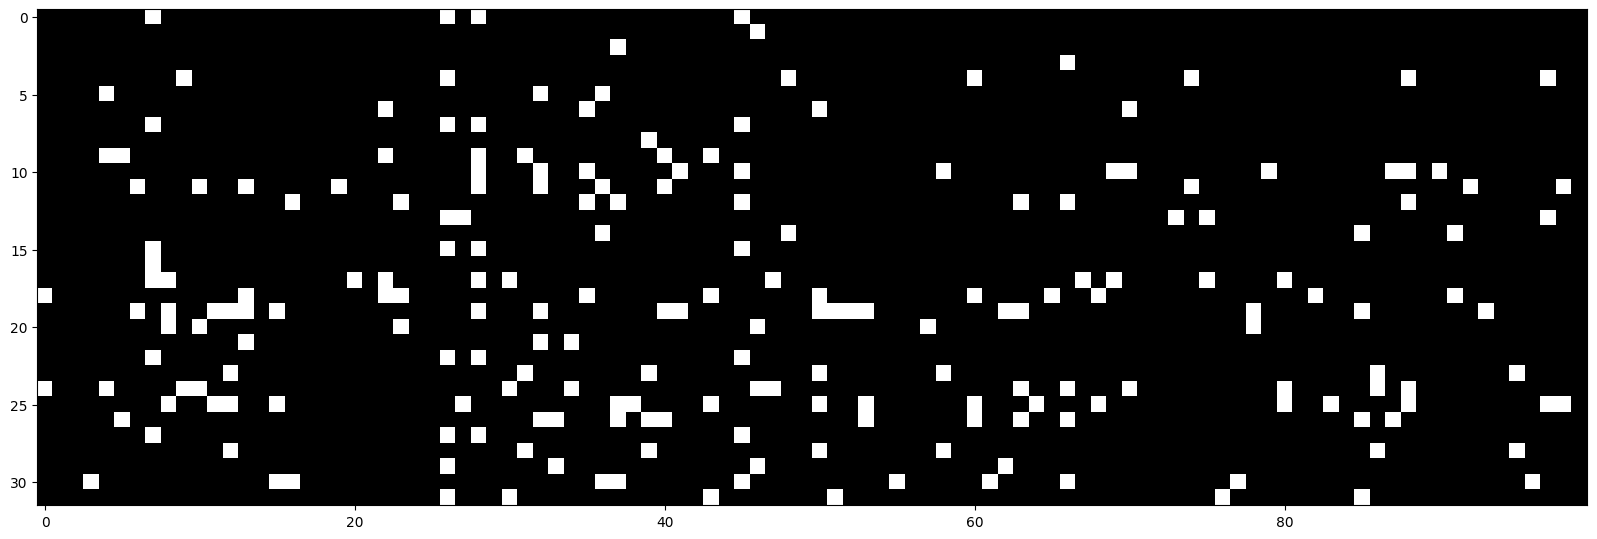

In [68]:
print((h.abs() > 0.99).float().mean().item())   # saturation %, should drop a lot

plt.hist(h.view(-1).tolist(), 50)
plt.show()

plt.hist(hpreact.view(-1).tolist(), 50)
plt.show()

plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')
plt.show()

### SUCCESS

# 3rd Bottleneck: Activation & Gradient Diagnostics 

Full Walkthrough: Setup → Forward Pass → Diagnostics

In [ ]:
# Linear class from Pytorch

class Linear:
    def __init__(self, fan_in, fan_out, bias=True, gain=1.0):
        self.weight = torch.randn((fan_in, fan_out), generator=g) * gain / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

tacks 4 hidden Linear → Tanh blocks plus a final output Linear (no Tanh after it — you don't squash logits before cross-entropy). gain=5/3 on every hidden layer applies your Phase 2 fix consistently across the whole stack; the output layer gets gain=1.0 (the default) since nothing follows it.

In [ ]:
g = torch.Generator().manual_seed(2147483647)

n_hidden = 100
layers = [
    Linear(n_embd * block_size, n_hidden, gain=5/3), Tanh(),
    Linear(n_hidden, n_hidden, gain=5/3), Tanh(),
    Linear(n_hidden, n_hidden, gain=5/3), Tanh(),
    Linear(n_hidden, n_hidden, gain=5/3), Tanh(),
    Linear(n_hidden, 27),
]

# TRY: Gain from 5/3 i/e what we found in phase 2, -> 1

with torch.no_grad():
    layers[-1].weight *= 0.1  # keep output layer less confident at init, same reasoning as Phase 1

parameters = [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

36127


In [ ]:
# Forward pass

Xb, Yb = Xtr[:32], Ytr[:32]

emb = C[Xb]
x = emb.view(emb.shape[0], -1)
for layer in layers:
    x = layer(x)
loss = F.cross_entropy(x, Yb)

for layer in layers:
    layer.out.retain_grad()
for p in parameters:
    p.grad = None
loss.backward()

'''
Bottleneck to watch for: layer.out.retain_grad() must run before loss.backward(), 
and must be called on every layer whose gradient you want to inspect afterward — 
x reassigned in the loop is a non-leaf tensor at every step, so without this call, 
layer.out.grad will be None
'''

## Step 4: Forward activation stats

**What we're seeing**: per-layer mean, std, and % saturated (|h| > 0.99) for every Tanh output in the stack, overlaid as histograms. This tells you whether your Phase 2 fix (the 5/3 gain) actually holds up once you have 4 stacked layers instead of 1 — watch specifically whether saturation % creeps upward in the later layers even though the first layer looks fine. That creep is variance compounding with depth, which a single global gain doesn't perfectly cancel.

layer 1 (Tanh): mean +0.01, std 0.73, saturated: 7.22%
layer 3 (Tanh): mean +0.00, std 0.68, saturated: 3.31%
layer 5 (Tanh): mean +0.02, std 0.66, saturated: 1.66%
layer 7 (Tanh): mean -0.03, std 0.65, saturated: 1.03%


Text(0.5, 1.0, 'activation distribution')

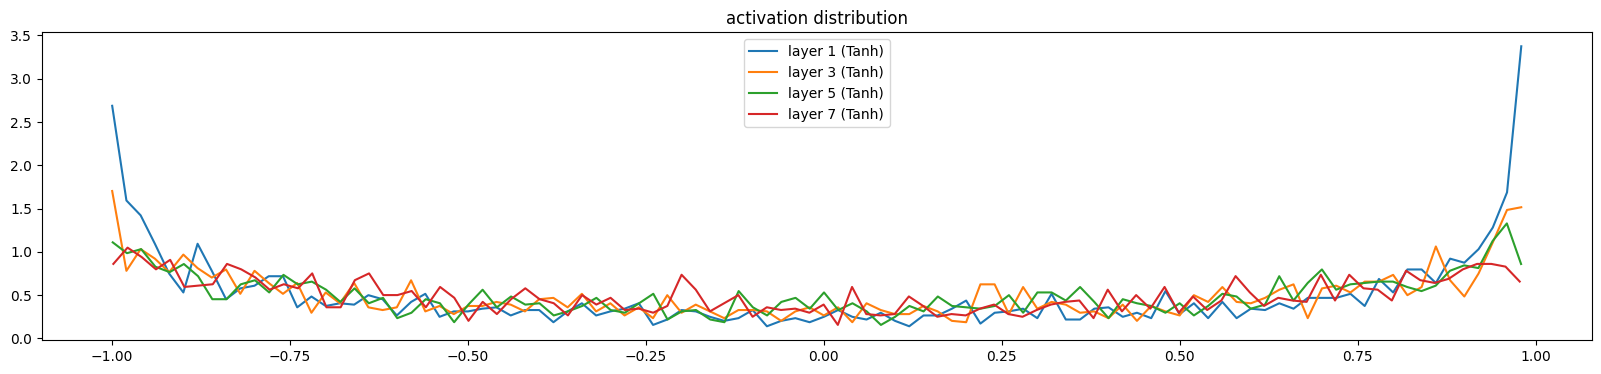

In [76]:
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers[:-1]):
    if isinstance(layer, Tanh):
        t = layer.out
        print(f'layer {i} ({layer.__class__.__name__}): mean {t.mean():+.2f}, std {t.std():.2f}, saturated: {(t.abs() > 0.99).float().mean()*100:.2f}%')
        hy, hx = torch.histogram(t.detach(), density=True)
        plt.plot(hx[:-1], hy)
        legends.append(f'layer {i} ({layer.__class__.__name__})')
plt.legend(legends)
plt.title('activation distribution')

layer 1 (Tanh): mean +1.962970e-06, std 3.989426e-04
layer 3 (Tanh): mean +6.265882e-06, std 3.691348e-04
layer 5 (Tanh): mean +2.351887e-06, std 3.476404e-04
layer 7 (Tanh): mean -1.510006e-06, std 3.168815e-04


Text(0.5, 1.0, 'gradient distribution')

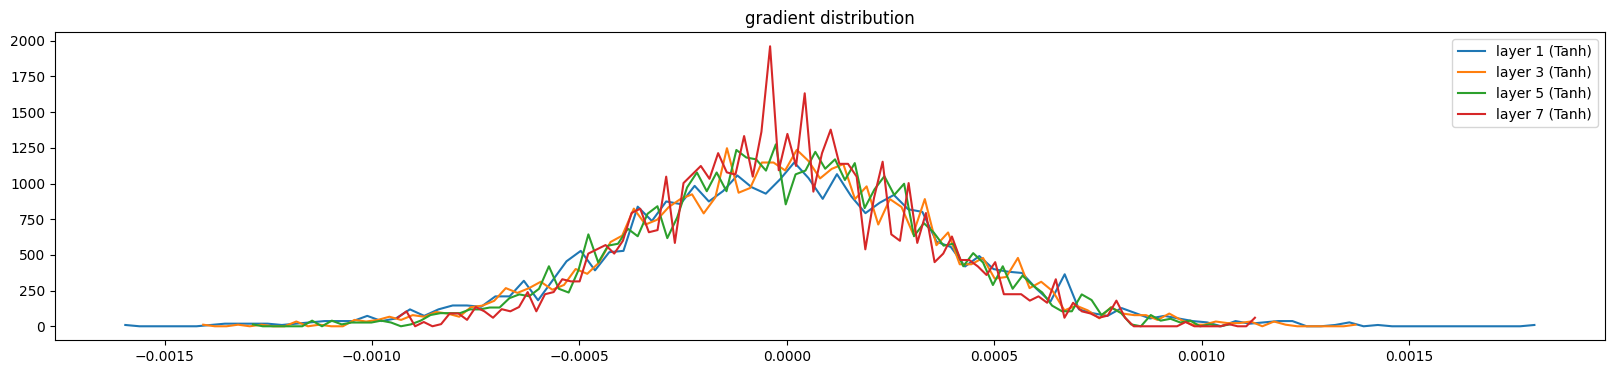

In [77]:
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers[:-1]):
    if isinstance(layer, Tanh):
        t = layer.out.grad
        print(f'layer {i} ({layer.__class__.__name__}): mean {t.mean():+e}, std {t.std():e}')
        hy, hx = torch.histogram(t.detach(), density=True)
        plt.plot(hx[:-1], hy)
        legends.append(f'layer {i} ({layer.__class__.__name__})')
plt.legend(legends)
plt.title('gradient distribution')

### Step 5: Backward gradient stats (Above)


**What we're seeing:** the same layout, but now for .grad of each Tanh output — this is checking whether learning signal is actually reaching the earlier layers or dying out (vanishing gradients) as it flows backward through 4 layers. A healthy stack shows roughly similar gradient std across all layers; a shrinking std toward layer 0 is the visual signature of vanishing gradients.

In [78]:
max_steps = 10000
batch_size = 32
lossi = []
ud = []

for i in range(max_steps):
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    emb = C[Xb]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb)

    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.1 if i < 5000 else 0.01
    with torch.no_grad():
        for p in parameters:
            p.data += -lr * p.grad

    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append([((lr * p.grad).std() / p.data.std()).log10().item() for p in parameters])

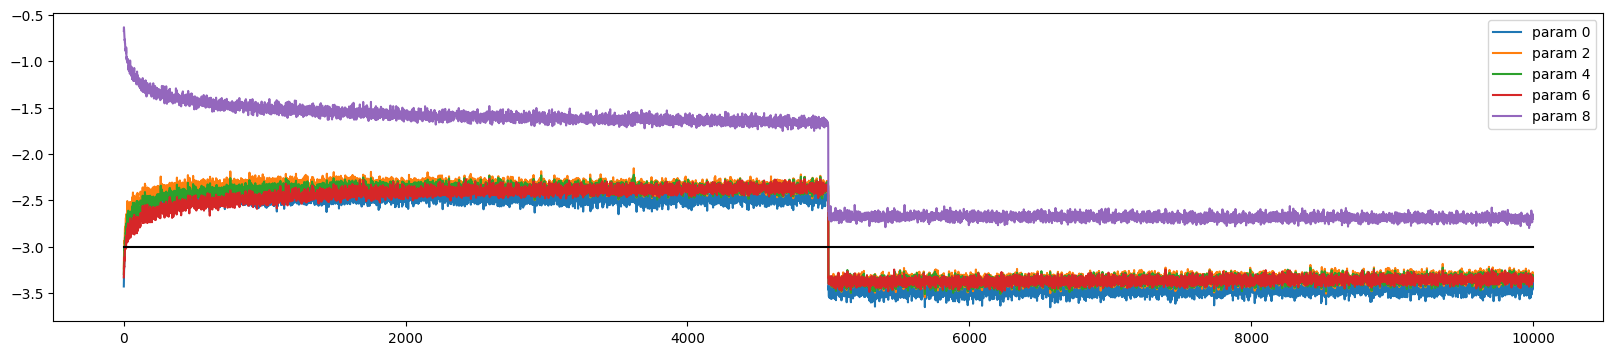

In [79]:
plt.figure(figsize=(20, 4))
legends = []
for i, p in enumerate(parameters):
    if p.ndim == 2:
        plt.plot([ud[j][i] for j in range(len(ud))])
        legends.append(f'param {i}')
plt.plot([0, len(ud)], [-3, -3], 'k')
plt.legend(legends)

### Step 6: Update:data ratio (needs a real training loop) (Above)

**What we're seeing:** per-parameter, how large each optimizer step is relative to that parameter's own scale, tracked over many training steps. Karpathy's target is log10(ratio) ≈ -3 — a flat line hugging the -3 reference means that parameter is being updated at a healthy pace all the way through training; a line sitting well above or below it means the effective learning rate is wrong for that specific parameter.

**Drop after 5k**: lr = 0.1 if i < 5000 else 0.01, this is causing the issue in update:data ratio

# Phase 4: Batch Normalization

#### ------- Without Refactoring with Pytorch -----------

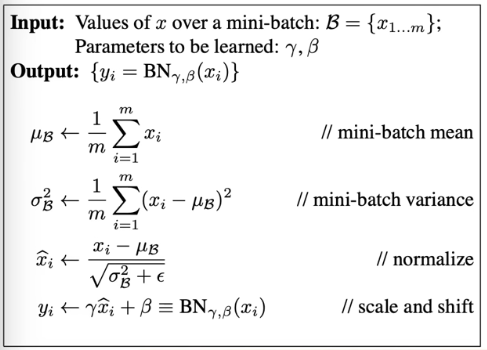

In [92]:
from PIL import Image
img = Image.open('part3-batch-norm.png')  # replace with your actual filename/path
img

This image is the original BatchNorm paper's (Ioffe & Szegedy, 2015) algorithm box — it's the exact four-step recipe your `bngain`/`bnbias`/`hpreact` code is implementing line-for-line. Here's the block with every new variable commented against the paper's notation.

Let me rebuild this from the image itself, step by step, matching each line of the algorithm box to one line of code — no extra framing, just the direct translation.

**The image, read as 4 steps:**

1. `μ_B ← (1/m) Σ x_i` — average the batch
2. `σ²_B ← (1/m) Σ (x_i − μ_B)²` — average squared distance from that average (variance)
3. `x̂_i ← (x_i − μ_B) / √(σ²_B + ε)` — subtract the mean, divide by the spread
4. `y_i ← γx̂_i + β` — multiply by a learned number, add a learned number

**The code, one line per step, nothing else:**

```python
hpreact = embcat @ W1
# this is "x" in the image — the values that go into steps 1-4

bnmeani = hpreact.mean(0, keepdim=True)
# ↑ this IS step 1 in the image (μ_B). Nothing more, nothing less.

bnstdi = hpreact.std(0, keepdim=True)
# ↑ this covers step 2 (σ²_B), just as std instead of variance — std = sqrt(variance),
# so this is the sqrt already taken, one step ahead of what the image shows separately.

hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
# ↑ this ONE line does BOTH step 3 and step 4 at the same time:
#     (hpreact - bnmeani) / bnstdi   =  step 3 (x̂_i)
#     bngain * (...) + bnbias        =  step 4 (γx̂_i + β)
```

**Variable-to-symbol, direct swap, nothing else attached:**

| Image symbol | Code variable |
|---|---|
| `x_i` | `hpreact` |
| `μ_B` | `bnmeani` |
| `σ²_B` | `bnstdi` (std, not variance — one step further along) |
| `x̂_i` | not a separate variable — computed inline as `(hpreact - bnmeani) / bnstdi` |
| `γ` | `bngain` |
| `β` | `bnbias` |
| `y_i` | `hpreact` (the same variable name gets reused for the final output) |

**That's the entire image.** Everything in it is 4 lines of math, and you already have all 4 lines. Nothing in the image mentions running averages at all — `bnmean_running`/`bnstd_running` are not from this picture. Those exist for a separate reason (no batch exists at inference time), which is what your last question already covered — keep that as a fully separate topic from this image, since mixing the two together is what was causing the confusion.

In [ ]:
# raw tensors, one hidden layer

n_embd = 10
n_hidden = 200
vocab_size = 27

g = torch.Generator().manual_seed(2147483647)
C  = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((n_embd * block_size, n_hidden), generator=g) * (5/3)/((n_embd * block_size)**0.5) # ~0.2
#                                                              Phase 2 Kaiming scaling (5/3 gain)
# b1 = None, bias before BatchNorm is redundant, since subtracting the batch mean cancels any constant offset.
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

bngain = torch.ones((1, n_hidden))          # learnable scale (gamma) — trained by backprop
bnbias = torch.zeros((1, n_hidden))         # learnable shift (beta) — trained by backprop
'''
Why bngain/bnbias are a separate story entirely (not stats, not running estimates):

bnmeani, bnstdi, bnmean_running, bnstd_running are all computed numbers — none of them are learned, 
none have gradients, they're just arithmetic on the data. bngain and bnbias are the opposite: 
they're trainable weights, exactly like W1. They start at 1 and 0 (meaning "do nothing extra" at first), 
and get updated by loss.backward() + gradient descent, just like every other weight in parameters. 
Their job is to let the network undo the normalization if it turns out that's better for a specific hidden unit
'''

bnmean_running = torch.zeros((1, n_hidden)) # tracks average mean across ALL batches seen so far — for inference
bnstd_running = torch.ones((1, n_hidden))   # tracks average std across ALL batches seen so far — for inference

parameters = [C, W1, W2, b2, bngain, bnbias]
for p in parameters:
    p.requires_grad = True

In [ ]:
# Training Loop

for i in range(max_steps):
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1

    # BatchNorm, by hand
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    
    '''
    Job 1 — bnmeani and bnstdi: used ONLY during training, recomputed every single step.

    These aren't stored anywhere persistent — they're thrown away after each step. 
    Every time a new batch comes in, you compute a fresh mean/std from that specific batch 
    and use it immediately to normalize that batch. Next step, new batch, new bnmeani/bnstdi, 
    computed from scratch again. There is nothing to "reuse" here — that's the whole point 
    of BatchNorm during training, it normalizes using whatever batch just walked in the door.
    '''
    #         weight *  batch                       + Bias
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    
    '''
    Job 2 — bnmean_running / bnstd_running: needed because at inference time, there is no batch.

    When you sample one name, you feed the model one single example, not a batch of 32. 
    You cannot compute a mean or std from a single example — a "mean" of one number is meaningless,
    and std of one number is undefined (or zero). So bnmeani/bnstdi literally cannot be computed 
    at inference time — there's no batch to compute them from. You need some pre-existing numbers, 
    calculated ahead of time, to normalize with instead.

    bnmean_running/bnstd_running are that pre-computed answer. During training, every step nudges 
    them slightly toward whatever bnmeani/bnstdi was for that step (0.999 * old + 0.001 * new). 
    After 200,000 steps, they've absorbed a smoothed average of every batch's mean/std across the 
    entire training run — effectively an estimate of "what's the mean/std over the whole dataset," 
    built up incrementally instead of computed all at once. By the end of training, you have a stable, 
    reusable number that works for a batch of 1.  
    '''

    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Yb)

    for p in parameters:
        p.grad = None
    loss.backward()
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad
        
'''
The running-stats update is the important line to understand: bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani. 
This is an exponential moving average (EMA) — each step nudges the running estimate 0.1% toward the current batch's mean, 
keeping 99.9% of the old running value. It's computed inside torch.no_grad() because you don't want gradients flowing 
through this bookkeeping
'''

In [83]:
# Eval — this is where bnmean_running/bnstd_running actually get used:

@torch.no_grad()
def split_loss(split):
    x, y = {'train': (Xtr, Ytr), 'val': (Xdev, Ydev), 'test': (Xte, Yte)}[split]
    emb = C[x]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1
    hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.260347366333008
val 2.265315532684326


#### -------- With Refactoring with Pytorch -------

In [7]:
# Deep 5 Layer Network

# The three classes — each wraps one operation and exposes .parameters() so a generic loop can collect 
# every learnable tensor across the whole stack, regardless of layer type:

class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        if self.training:
            xmean = x.mean(0, keepdim=True)
            xvar = x.var(0, keepdim=True)
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        self.out = self.gamma * xhat + self.beta
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]


class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

In [9]:
vocab_size = 27

In [ ]:
n_embd = 10
n_hidden = 100
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embd), generator=g)
layers = [
    Linear(n_embd * block_size, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size, bias=False), BatchNorm1d(vocab_size), # No Tanh at last ALWAYS
]

with torch.no_grad():
    layers[-1].gamma *= 0.1
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3  # gain — try 5/3 vs 1.0, see diagnostics below
            '''
            5/3 ≈ 1.667 is the gain for tanh — a correction factor applied on top of standard weight init 
            to counteract exactly what tanh does to signal variance as it passes through.
            
            std = gain / fan_in**0.5
            gain = 1.0 → linear layers, sigmoid
            gain = 5/3 ≈ 1.667 → tanh (compensates for the slope-shrinkage above)
            gain = √2 ≈ 1.414 → ReLU (Kaiming/He init — compensates for ReLU zeroing out ~half the values, a bigger correction than tanh needs)
            '''
            

parameters = [C] + [p for layer in layers for p in layer.parameters()]
for p in parameters:
    p.requires_grad = True

In [11]:
len(parameters)

19

In [14]:
# Training Loop

max_steps = 200000
batch_size = 32
lossi, ud = [], []

for i in range(max_steps):
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    emb = C[Xb]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb)

    for layer in layers:
        layer.out.retain_grad()
    for p in parameters:
        p.grad = None
    loss.backward()

    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])

      0/ 200000: 3.2870
  10000/ 200000: 2.3578
  20000/ 200000: 2.1043
  30000/ 200000: 1.9646
  40000/ 200000: 2.2144
  50000/ 200000: 2.2266
  60000/ 200000: 1.7339
  70000/ 200000: 2.1748
  80000/ 200000: 2.1895
  90000/ 200000: 1.8281
 100000/ 200000: 2.3635
 110000/ 200000: 2.2015
 120000/ 200000: 2.1032
 130000/ 200000: 1.8564
 140000/ 200000: 1.8050
 150000/ 200000: 1.9258
 160000/ 200000: 1.8762
 170000/ 200000: 1.8334
 180000/ 200000: 2.2314
 190000/ 200000: 2.0513


layer 2 (      Tanh): mean -0.01, std 0.69, saturated: 14.03%
layer 5 (      Tanh): mean -0.02, std 0.72, saturated: 16.91%
layer 8 (      Tanh): mean -0.00, std 0.75, saturated: 15.75%
layer 11 (      Tanh): mean +0.02, std 0.77, saturated: 16.78%
layer 14 (      Tanh): mean -0.02, std 0.79, saturated: 18.72%


' \nWhat it shows: the actual output values of tanh at each layer, overlaid as histograms — one curve per layer.\n\nHow to read it:\n\nGood: curves for different layers roughly overlap, centered near 0, spread across most of (-1, 1) \nrather than piled at the edges. Low saturation % (a few percent).\n\nBad: curves pile up sharply at -1/+1 (saturation, dead-gradient risk) or collapse into a narrow spike \nnear 0 (nonlinearity wasted, near-linear regime). Curves drifting apart layer-to-layer \n(later layers much narrower/wider than earlier ones) means variance isn\'t holding steady with depth.\n\nWhat you\'re using it for: confirming your init/BatchNorm is keeping every layer in a "usable" zone of tanh, not just the first one.\n'

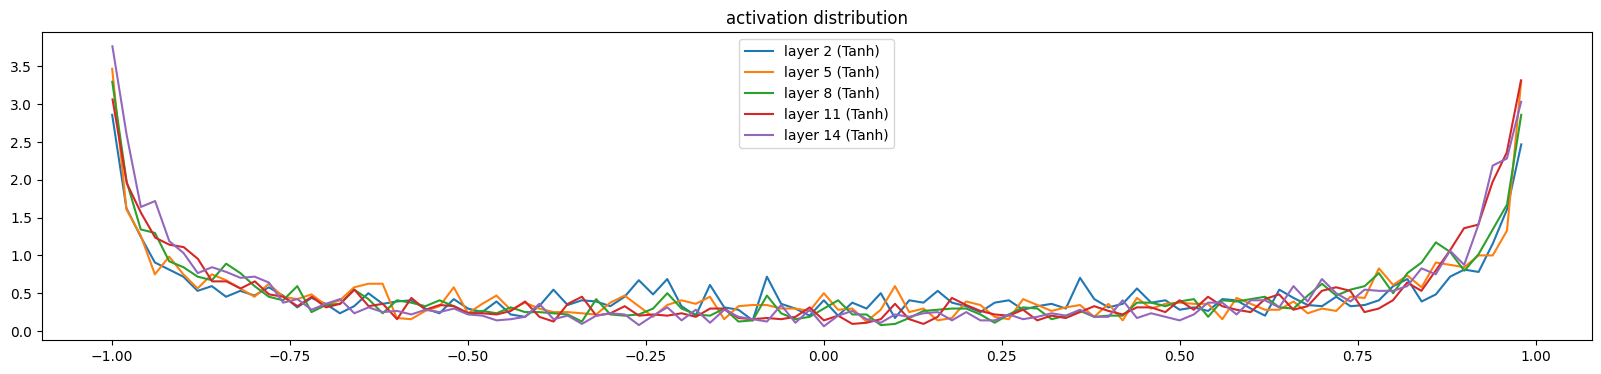

In [18]:
# Diagnostics — same three plots from Phase 3, now applied to the 5-layer BatchNorm stack:

# 1. Forward activations
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers[:-1]):
    if isinstance(layer, Tanh):
        t = layer.out
        print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' %
              (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__})')
plt.legend(legends)
plt.title('activation distribution')


''' 
What it shows: the actual output values of tanh at each layer, overlaid as histograms — one curve per layer.

How to read it:

Good: curves for different layers roughly overlap, centered near 0, spread across most of (-1, 1) 
rather than piled at the edges. Low saturation % (a few percent).

Bad: curves pile up sharply at -1/+1 (saturation, dead-gradient risk) or collapse into a narrow spike 
near 0 (nonlinearity wasted, near-linear regime). Curves drifting apart layer-to-layer 
(later layers much narrower/wider than earlier ones) means variance isn't holding steady with depth.

What you're using it for: confirming your init/BatchNorm is keeping every layer in a "usable" zone of tanh, not just the first one.
'''

layer 2 (      Tanh): mean +0.000000, std 3.413536e-03
layer 5 (      Tanh): mean -0.000000, std 3.279547e-03
layer 8 (      Tanh): mean +0.000000, std 3.261172e-03
layer 11 (      Tanh): mean +0.000000, std 3.533220e-03
layer 14 (      Tanh): mean -0.000000, std 3.843107e-03


"\nWhat it shows: how much gradient is actually flowing backward through each layer's tanh output during backprop.\n\nHow to read it:\n\nGood: std stays roughly the same order of magnitude across layers (your data: 2.64e-3 → 1.95e-3, mild and gradual — fine).\n\nBad: std shrinks by orders of magnitude going backward (1e-3 → 1e-6 → 1e-9) — that's vanishing gradients, \nmeaning early layers barely learn. Or std blows up going backward — exploding gradients, unstable training.\n\nWhat you're using it for: checking whether depth itself is killing learning signal before it reaches the earliest layers — \nthis is the plot most likely to catch a problem that's invisible in the forward-activation plot.\n"

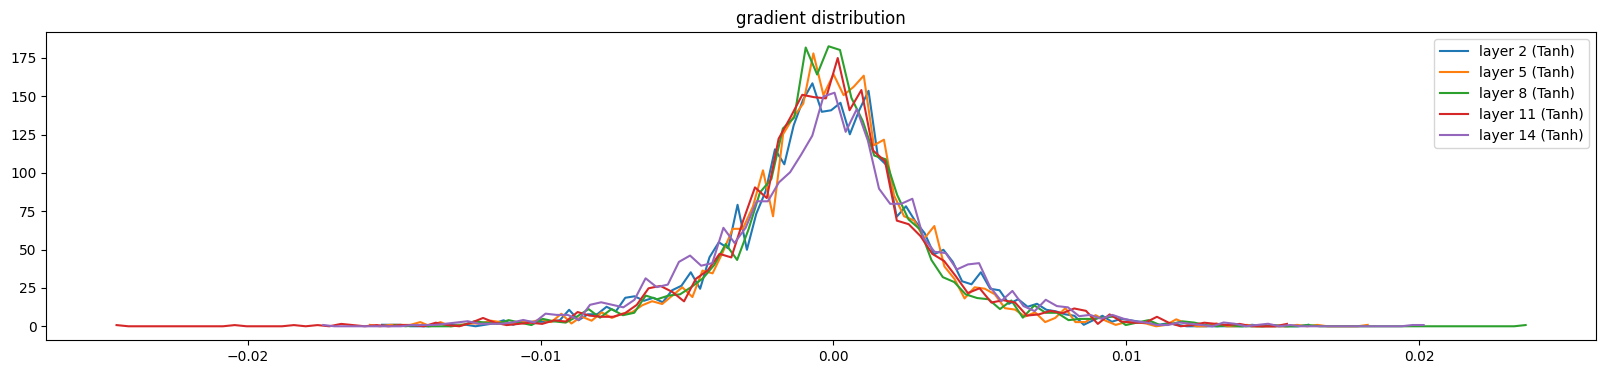

In [19]:
# 2. Backward gradients
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers[:-1]):
    if isinstance(layer, Tanh):
        t = layer.out.grad
        print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__})')
plt.legend(legends)
plt.title('gradient distribution')


'''
What it shows: how much gradient is actually flowing backward through each layer's tanh output during backprop.

How to read it:

Good: std stays roughly the same order of magnitude across layers (your data: 2.64e-3 → 1.95e-3, mild and gradual — fine).

Bad: std shrinks by orders of magnitude going backward (1e-3 → 1e-6 → 1e-9) — that's vanishing gradients, 
meaning early layers barely learn. Or std blows up going backward — exploding gradients, unstable training.

What you're using it for: checking whether depth itself is killing learning signal before it reaches the earliest layers — 
this is the plot most likely to catch a problem that's invisible in the forward-activation plot.
'''

weight   (27, 10) | mean +0.000000 | std 1.496282e-02 | grad:data ratio 1.370130e-02
weight  (30, 100) | mean +0.000085 | std 7.868121e-03 | grad:data ratio 1.919725e-02
weight (100, 100) | mean +0.000060 | std 5.040717e-03 | grad:data ratio 2.042102e-02
weight (100, 100) | mean -0.000086 | std 5.160939e-03 | grad:data ratio 2.125960e-02
weight (100, 100) | mean +0.000044 | std 5.189625e-03 | grad:data ratio 2.191136e-02
weight (100, 100) | mean -0.000013 | std 5.230158e-03 | grad:data ratio 2.274973e-02
weight  (100, 27) | mean +0.000052 | std 9.163717e-03 | grad:data ratio 2.774595e-02


'\nWhat it shows: the actual gradient values for each weight matrix (not activations — the parameters themselves), \nplus a printed ratio comparing gradient scale to the weight\'s own scale, at this one instant.\n\nHow to read it:\n\nGood: all weight matrices\' gradient distributions look similar in shape/spread to each other; the printed grad:data ratio \nnumbers are all in a similar order of magnitude (yours ranged 8e-3 to 1.16e-1 — a bit of spread, but not wildly different \nby many orders of magnitude).\n\nBad: one specific layer\'s gradient is dramatically larger or smaller than the rest — that layer is either being updated\nway too aggressively or barely at all relative to its peers.\n\nWhat you\'re using it for: a snapshot check — "right now, at this training step, is any one layer\'s weight update wildly \nout of line with the others?" It\'s the single-instant version of plot 4 below.\n'

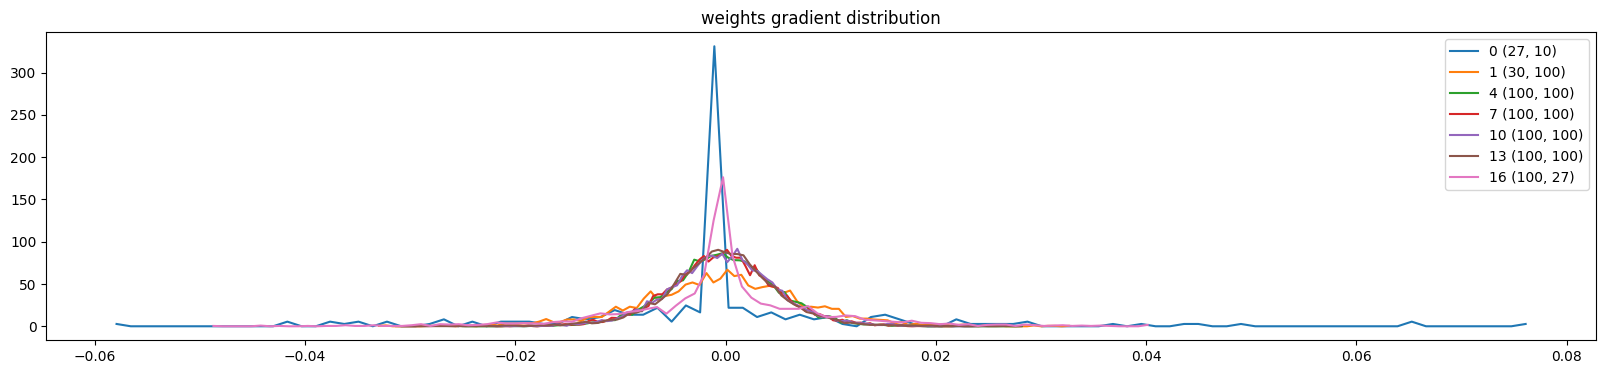

In [20]:
# 3. Weight gradient distribution (new — per-parameter, not per-activation)
plt.figure(figsize=(20, 4))
legends = []
for i, p in enumerate(parameters):
    t = p.grad
    if p.ndim == 2:
        print('weight %10s | mean %+f | std %e | grad:data ratio %e' %
              (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution')

'''
What it shows: the actual gradient values for each weight matrix (not activations — the parameters themselves), 
plus a printed ratio comparing gradient scale to the weight's own scale, at this one instant.

How to read it:

Good: all weight matrices' gradient distributions look similar in shape/spread to each other; the printed grad:data ratio 
numbers are all in a similar order of magnitude (yours ranged 8e-3 to 1.16e-1 — a bit of spread, but not wildly different 
by many orders of magnitude).

Bad: one specific layer's gradient is dramatically larger or smaller than the rest — that layer is either being updated
way too aggressively or barely at all relative to its peers.

What you're using it for: a snapshot check — "right now, at this training step, is any one layer's weight update wildly 
out of line with the others?" It's the single-instant version of plot 4 below.
'''

'\nWhat it shows: for every weight matrix, log10((lr * grad).std() / data.std()), plotted across the entire training run — \nthis is plot 3\'s ratio, but as a movie instead of a snapshot.\n\nHow to read it:\n\nGood: lines settle and stay roughly flat, hugging the black -3 reference line, for most of training. \nThat means each parameter\'s update size, relative to its own scale, is consistently well-calibrated \n(~1/1000th the parameter\'s scale per step) throughout training, not just at one lucky moment.\n\nBad: a line sits persistently far above -3 (that parameter is being updated too aggressively relative \nto its scale — risk of instability) or far below -3 (barely updating — that parameter is effectively stuck/undertrained). \nA line that\'s fine early but drifts badly later means something is destabilizing partway through training.\n\nWhat you\'re using it for: the most direct diagnostic for "is my learning rate actually appropriate for every parameter, \nfor the whole run" — not

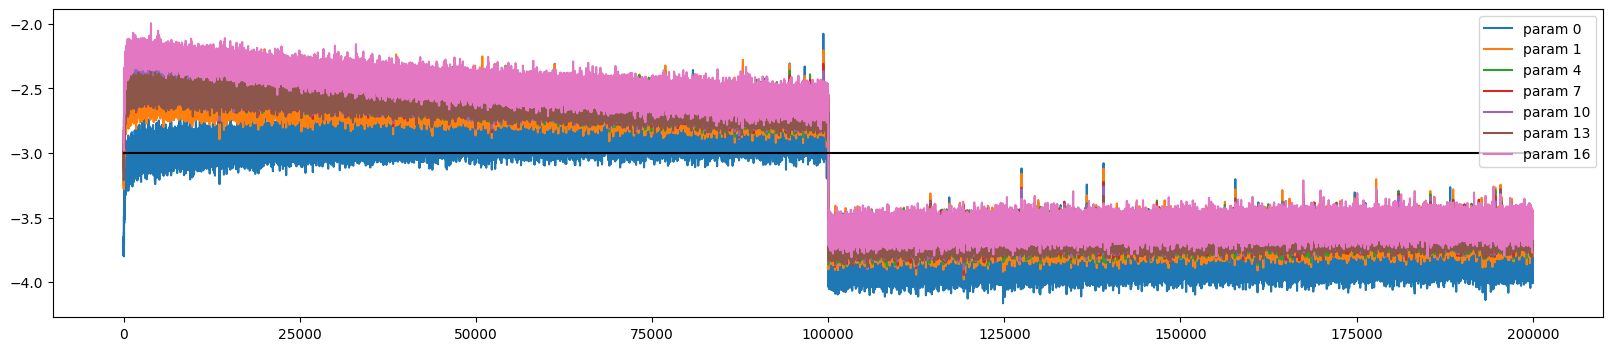

In [21]:
# 4. Update:data ratio over training (identical to Phase 3)
plt.figure(figsize=(20, 4))
legends = []
for i, p in enumerate(parameters):
    if p.ndim == 2:
        plt.plot([ud[j][i] for j in range(len(ud))])
        legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k')
plt.legend(legends)


'''
What it shows: for every weight matrix, log10((lr * grad).std() / data.std()), plotted across the entire training run — 
this is plot 3's ratio, but as a movie instead of a snapshot.

How to read it:

Good: lines settle and stay roughly flat, hugging the black -3 reference line, for most of training. 
That means each parameter's update size, relative to its own scale, is consistently well-calibrated 
(~1/1000th the parameter's scale per step) throughout training, not just at one lucky moment.

Bad: a line sits persistently far above -3 (that parameter is being updated too aggressively relative 
to its scale — risk of instability) or far below -3 (barely updating — that parameter is effectively stuck/undertrained). 
A line that's fine early but drifts badly later means something is destabilizing partway through training.

What you're using it for: the most direct diagnostic for "is my learning rate actually appropriate for every parameter, 
for the whole run" — not just whether loss goes down, but whether it's going down for the right reasons across every layer, the whole time.
'''

In [22]:
@torch.no_grad()
def split_loss(split):
    x, y = {'train': (Xtr, Ytr), 'val': (Xdev, Ydev), 'test': (Xte, Yte)}[split]
    emb = C[x]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, y)
    print(split, loss.item())

for layer in layers:
    layer.training = False
split_loss('train')
split_loss('val')

train 2.0123212337493896
val 2.084101438522339


In [27]:
# Sampling

g = torch.Generator().manual_seed(214748347 + 10)
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        x = emb.view(emb.shape[0], -1)
        for layer in layers:
            x = layer(x)
        probs = F.softmax(x, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[i] for i in out))

emilie.
ernaviennilsis.
tyrichellaize.
coladsha.
man.
katdalin.
lavallial.
keon.
jenuzley.
mark.
meralynn.
emmena.
emelyn.
armi.
javy.
kaxpirlin.
kacy.
mariyah.
ter.
briel.
